# 03 Smoothing simulation: what the predictions are worth
Compares no smoothing, always-burn, and model-armed predictive smoothing on the test traces, then scales to a 100 MW site. Change the parameters in `SimParams` to explore other grid limits, floors or actuator latencies.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
# make `src` importable whether the notebook runs from notebooks/ or the repo root
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
sys.path.insert(0, ROOT); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

In [2]:
from src.simulate import SimParams, run
sp = SimParams()  # e.g. SimParams(ramp_limit_frac_per_s=0.05, actuator_latency_s=2.0)
sp

SimParams(ramp_limit_frac_per_s=0.1, floor_frac=0.8, peak_window_s=60.0, actuator_latency_s=1.0, arm_hold_s=6.0, safety=0.9, forecast_trigger_frac=0.15, site_mw=100.0, price_per_mwh=80.0, site_instances=400, site_hours=2.0)

In [3]:
res = run(sp)
res['summary'].round(2)

                    down_violations_per_node_hour  all_violations_per_node_hour  median_max_down_ramp_pct_peak_per_s  extra_energy_pct  deferred_compute_pct  down_violation_cut_pct  all_violation_cut_pct
strategy                                                                                                                                                                                                   
raw                                        184.26                        351.75                                70.86              0.00                  0.00                    0.00                   0.00
always_burn                                171.84                        343.28                                19.71              6.78                  0.00                    6.74                   2.41
predictive                                  29.82                        210.02                                58.71              2.58                  0.00                   83.81    

,down_violations_per_node_hour,all_violations_per_node_hour,median_max_down_ramp_pct_peak_per_s,extra_energy_pct,deferred_compute_pct,down_violation_cut_pct,all_violation_cut_pct
strategy,,,,,,,
raw,184.26,351.75,70.86,0.00,0.00,0.00,0.00
always_burn,171.84,343.28,19.71,6.78,0.00,6.74,2.41
predictive,29.82,210.02,58.71,2.58,0.00,83.81,40.29
predictive_preramp,29.56,280.29,58.71,1.55,2.95,83.96,20.32
reactive,154.77,312.84,68.63,0.57,0.00,16.00,11.06
always_on_limiter,0.00,171.77,9.00,2.94,0.00,100.00,51.17


## Before / after on example windows

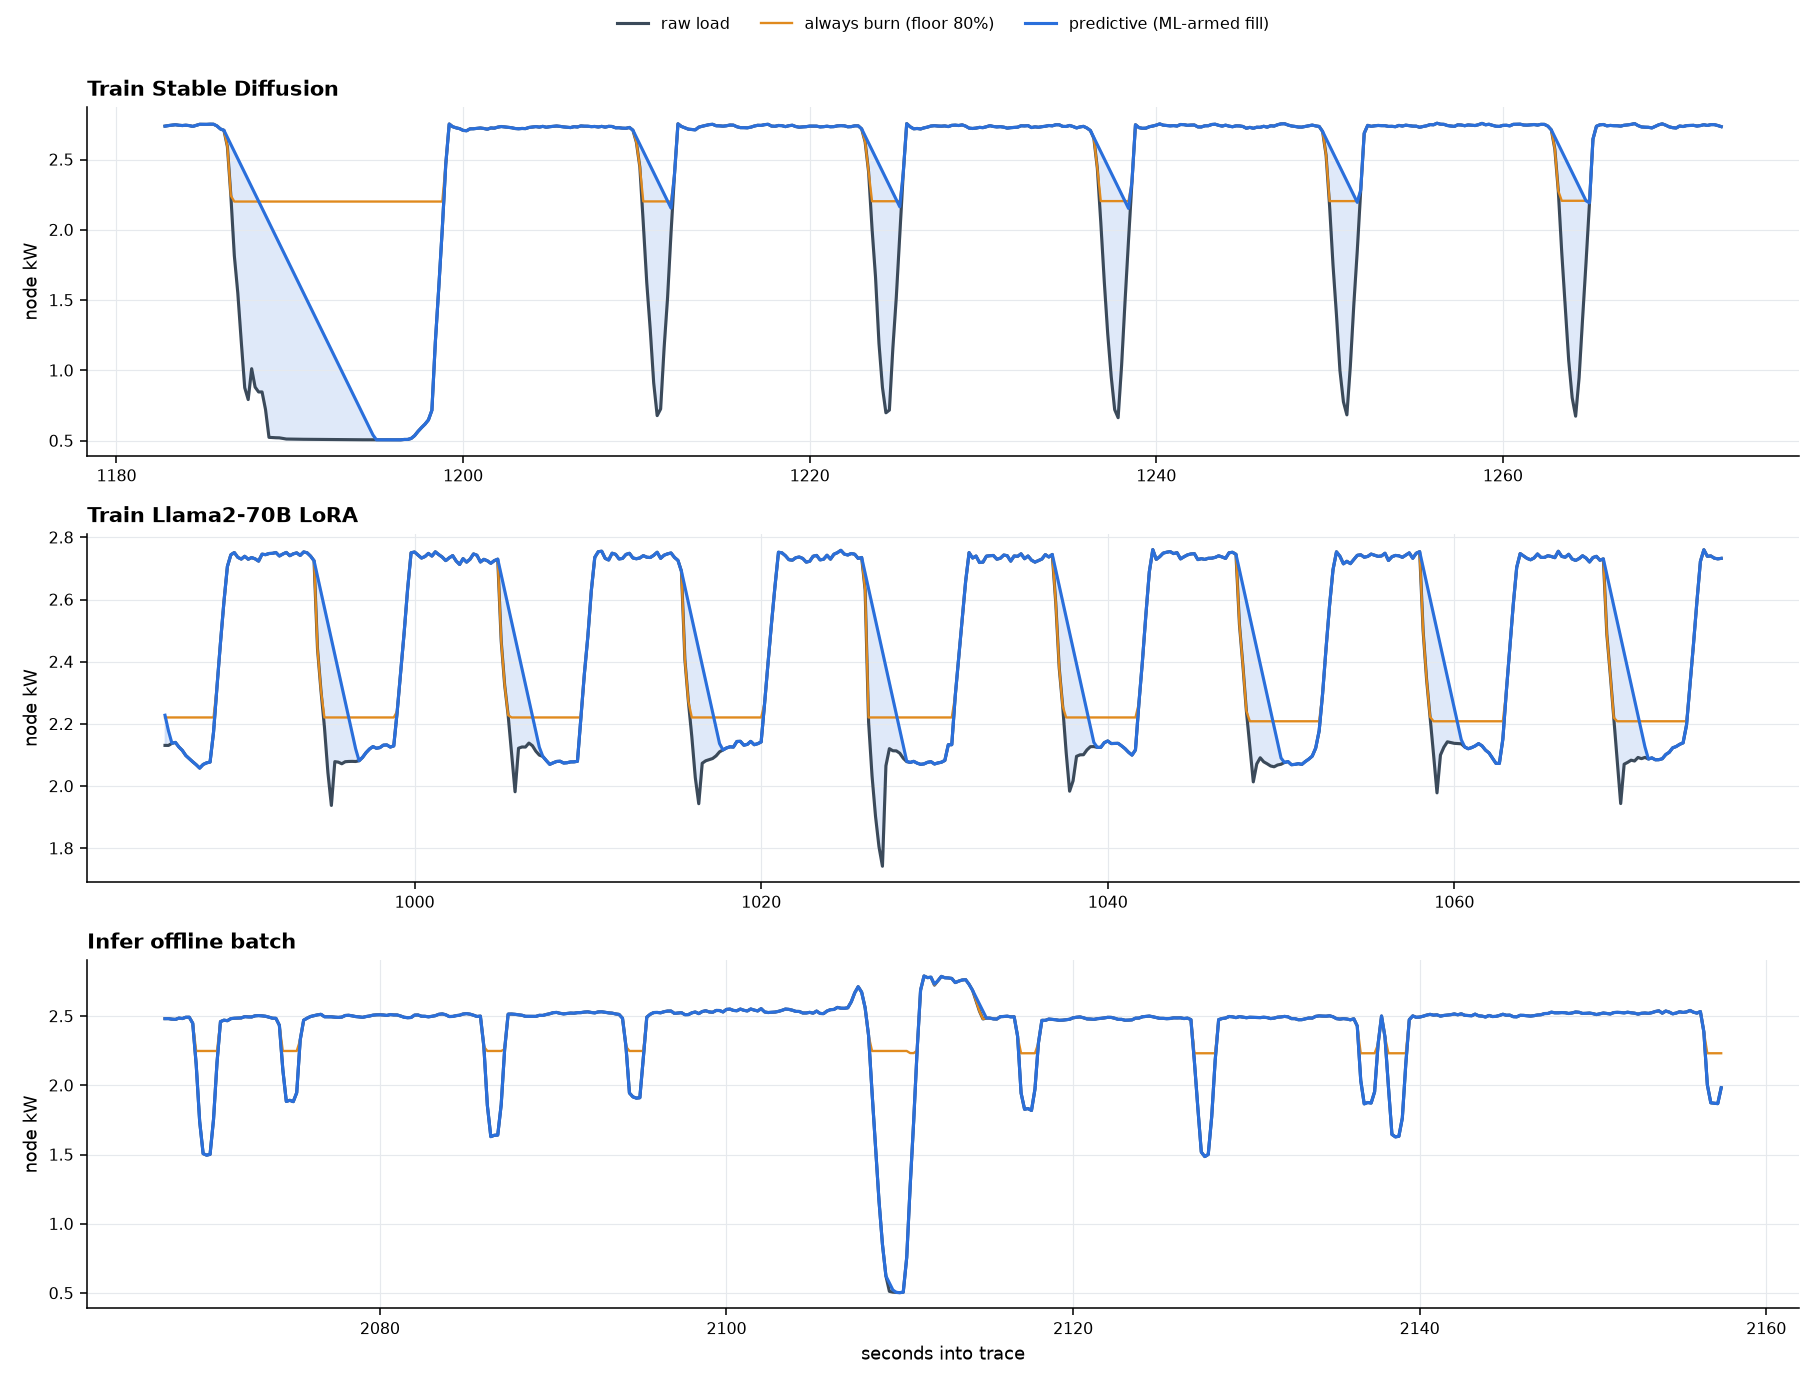

In [4]:
display(Image('reports/figures/smoothing_before_after.png'))

## By workload

In [5]:
res['by_workload'].pivot(index='workload', columns='strategy', values='down_violations_per_node_hour').round(1)

strategy,always_burn,always_on_limiter,predictive,predictive_preramp,raw,reactive
workload,,,,,,
inference_offline,136.3,0.0,144.3,141.0,229.0,155.3
inference_online_finite,28.4,0.0,11.3,11.3,72.1,61.4
inference_online_rate,138.6,0.0,127.3,127.3,151.9,15.6
train_llama2_70b_lora,292.2,0.0,2.7,2.7,295.0,289.6
train_stable_diffusion,150.8,0.0,14.5,14.4,152.0,131.7


## 100 MW site, yearly cost of the extra energy at $80/MWh

,case,strategy,avg_site_load_mw,extra_energy_pct,extra_mwh_per_year,extra_cost_usd_per_year,down_violations_per_hour,max_down_ramp_mw_per_s
0,synchronized,raw,79.75,0.00,0.00,0.00,184.26,NaN
1,synchronized,always_burn,79.75,6.78,47382.55,3790604.07,171.84,NaN
2,synchronized,predictive,79.75,2.58,17995.55,1439643.72,29.82,NaN
3,synchronized,predictive_preramp,79.75,1.55,10822.86,865829.15,29.56,NaN
4,synchronized,reactive,79.75,0.57,4011.56,320924.81,154.77,NaN
5,synchronized,always_on_limiter,79.75,2.94,20506.05,1640483.80,0.00,NaN
6,random_offsets,raw,77.83,0.00,0.00,0.00,0.00,2.08
7,random_offsets,always_burn,77.83,7.50,51122.61,4089808.56,0.00,1.01
8,random_offsets,predictive,77.83,2.35,15990.38,1279230.26,0.00,1.20
9,random_offsets,predictive_preramp,77.83,1.26,8610.27,688821.88,0.00,1.23


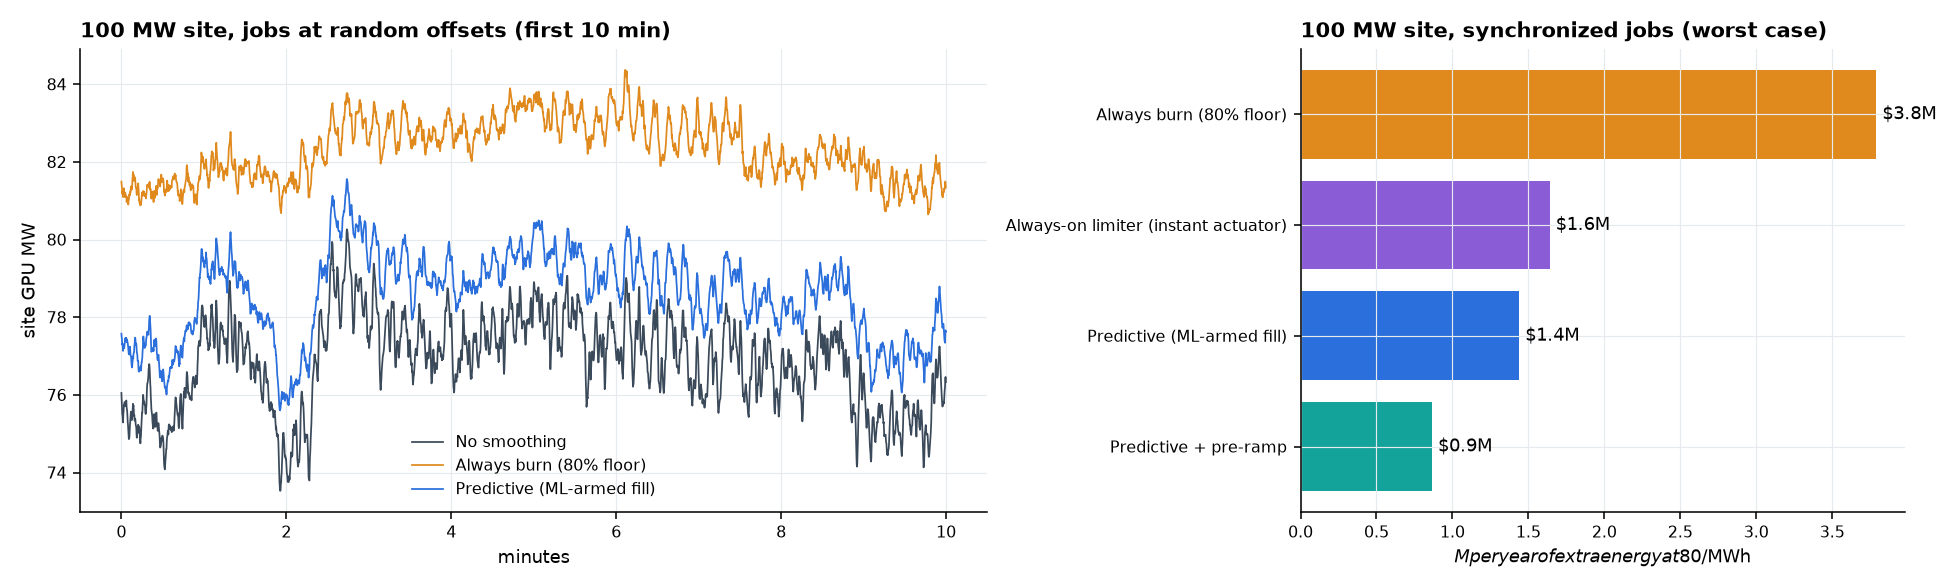

In [6]:
display(res['site'].round(2))
display(Image('reports/figures/site_scaleup.png'))

## Sensitivity: actuator latency
Prediction only matters if the fill or storage cannot react instantly.

In [7]:
rows = []
for lat in [0.2, 0.5, 1.0, 2.0, 3.0]:
    r = run(SimParams(actuator_latency_s=lat), log=lambda *_: None)['summary']
    rows.append({'latency_s': lat, **{f'{s}_cut_%': r.loc[s, 'down_violation_cut_pct'] for s in ['predictive', 'reactive', 'always_on_limiter']},
                 'predictive_energy_%': r.loc['predictive', 'extra_energy_pct']})
run(sp, log=lambda *_: None)  # restore default outputs
pd.DataFrame(rows).round(1)

,latency_s,predictive_cut_%,reactive_cut_%,always_on_limiter_cut_%,predictive_energy_%
0,0.2,83.8,39.5,100.0,2.7
1,0.5,83.9,16.4,100.0,2.6
2,1.0,83.8,16.0,100.0,2.6
3,2.0,83.7,16.4,100.0,2.6
4,3.0,83.3,16.4,100.0,2.5
